# Human Activity Recognition Using Machine Learning

## Member 2: KNN and Decision Tree Classification

**Dataset:** UCI Human Activity Recognition Using Smartphones

### Responsibilities

1. Understand supervised machine learning.
2. Load the preprocessed dataset.
3. Implement the K-Nearest Neighbors (KNN) algorithm.
4. Implement the Decision Tree algorithm.
5. Train both classification models.
6. Generate predictions.
7. Evaluate models using accuracy, precision, recall, and F1-score.
8. Generate confusion matrices.
9. Compare the performance of KNN and Decision Tree.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os

DATASET_PATH = "../UCI HAR Dataset"

# Load training features and labels
X_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train", "X_train.txt"),
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train", "y_train.txt"),
    header=None
).values.ravel()

# Load testing features and labels
X_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test", "X_test.txt"),
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test", "y_test.txt"),
    header=None
).values.ravel()

print("Dataset loaded successfully!")
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Dataset loaded successfully!
Training features: (7352, 561)
Training labels: (7352,)
Testing features: (2947, 561)
Testing labels: (2947,)


In [3]:
print("Training data information:")
print("Number of training samples:", X_train.shape[0])
print("Number of features:", X_train.shape[1])

print("\nTesting data information:")
print("Number of testing samples:", X_test.shape[0])

print("\nUnique activity labels:")
print(np.unique(y_train))

print("\nMissing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Training data information:
Number of training samples: 7352
Number of features: 561

Testing data information:
Number of testing samples: 2947

Unique activity labels:
[1 2 3 4 5 6]

Missing values in training data: 0
Missing values in testing data: 0


In [4]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data shape: (7352, 561)
Scaled testing data shape: (2947, 561)


In [5]:
# Create the KNN classifier
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [6]:
# Predict activities using KNN
y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN predictions generated successfully!")

print("\nFirst 20 Actual Labels:")
print(y_test[:20])

print("\nFirst 20 Predicted Labels:")
print(y_pred_knn[:20])

KNN predictions generated successfully!

First 20 Actual Labels:
[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5]

First 20 Predicted Labels:
[5 5 5 5 5 5 5 5 5 4 5 5 5 5 5 5 5 5 5 5]


In [7]:
# Calculate KNN evaluation metrics

knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test, y_pred_knn, average="weighted"
)

knn_recall = recall_score(
    y_test, y_pred_knn, average="weighted"
)

knn_f1 = f1_score(
    y_test, y_pred_knn, average="weighted"
)

print("KNN Model Performance")
print("---------------------")
print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1-score :", round(knn_f1, 4))

KNN Model Performance
---------------------
Accuracy : 0.8802
Precision: 0.8883
Recall   : 0.8802
F1-score : 0.879


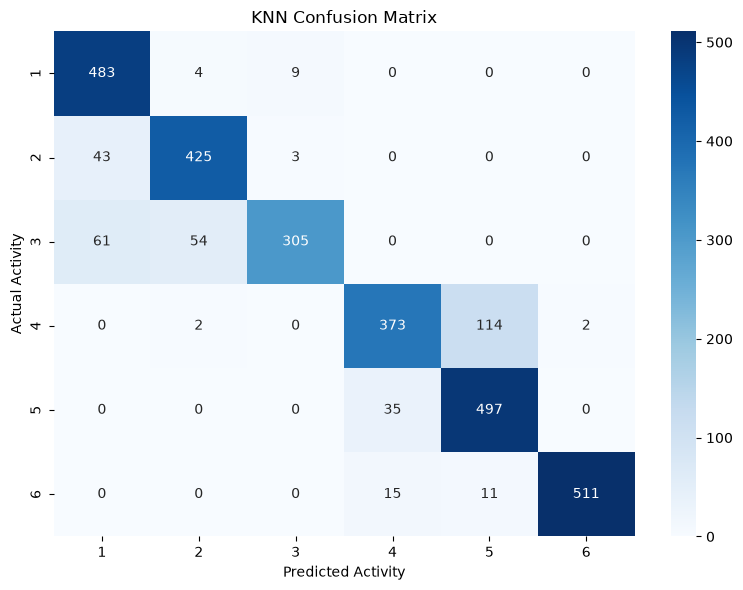

In [8]:
# Generate KNN confusion matrix
knn_cm = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(8, 6))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5, 6],
    yticklabels=[1, 2, 3, 4, 5, 6]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()
plt.show()

In [9]:
# Create the Decision Tree classifier
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [10]:
# Predict activities using Decision Tree
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree predictions generated successfully!")

print("\nFirst 20 Actual Labels:")
print(y_test[:20])

print("\nFirst 20 Predicted Labels:")
print(y_pred_dt[:20])

Decision Tree predictions generated successfully!

First 20 Actual Labels:
[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5]

First 20 Predicted Labels:
[5 5 5 5 5 4 4 5 5 5 5 5 5 5 5 5 4 5 5 5]


In [11]:
# Calculate Decision Tree evaluation metrics

dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test, y_pred_dt, average="weighted"
)

dt_recall = recall_score(
    y_test, y_pred_dt, average="weighted"
)

dt_f1 = f1_score(
    y_test, y_pred_dt, average="weighted"
)

print("Decision Tree Model Performance")
print("--------------------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1-score :", round(dt_f1, 4))

Decision Tree Model Performance
--------------------------------
Accuracy : 0.8622
Precision: 0.8633
Recall   : 0.8622
F1-score : 0.8617


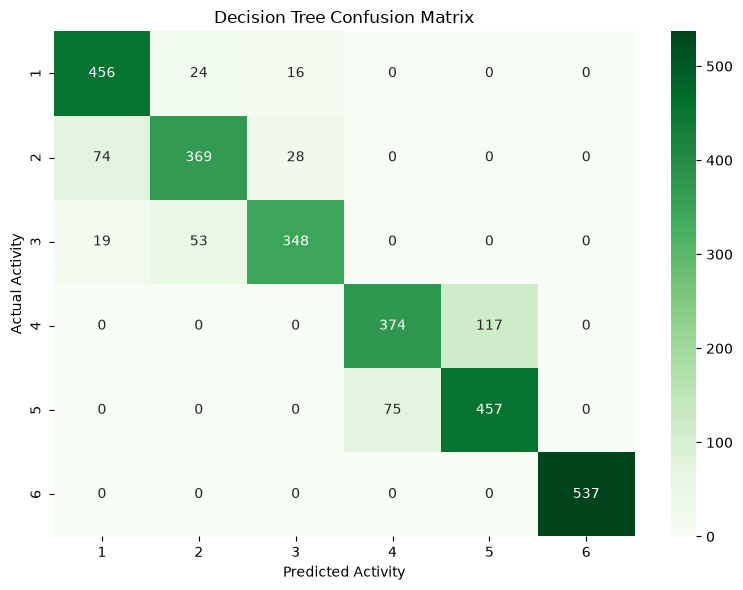

In [12]:
# Generate Decision Tree confusion matrix
dt_cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(8, 6))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[1, 2, 3, 4, 5, 6],
    yticklabels=[1, 2, 3, 4, 5, 6]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.tight_layout()
plt.show()

In [13]:
# Create a comparison table

model_comparison = pd.DataFrame({
    "Model": ["KNN", "Decision Tree"],
    "Accuracy": [knn_accuracy, dt_accuracy],
    "Precision": [knn_precision, dt_precision],
    "Recall": [knn_recall, dt_recall],
    "F1-Score": [knn_f1, dt_f1]
})

print("Classification Model Performance Comparison:")
display(model_comparison.round(4))

Classification Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.8802,0.8883,0.8802,0.8790
1,Decision Tree,0.8622,0.8633,0.8622,0.8617


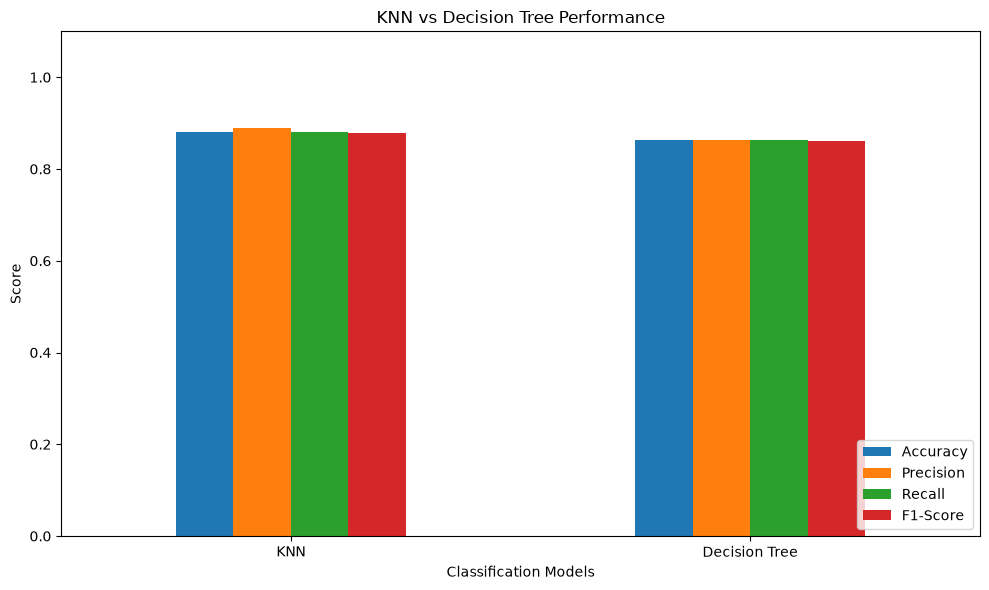

In [14]:
# Visual comparison of model performance

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

model_comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("KNN vs Decision Tree Performance")
plt.ylabel("Score")
plt.xlabel("Classification Models")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Classification Results and Observations

Two supervised machine learning algorithms were implemented and evaluated for Human Activity Recognition.

### 1. K-Nearest Neighbors (KNN)
- The KNN algorithm was implemented using 5 nearest neighbors.
- Feature scaling was performed using StandardScaler.
- The model was trained using the training dataset.
- Predictions were generated using the testing dataset.
- Accuracy, precision, recall, and F1-score were calculated.
- A confusion matrix was generated to visualize classification performance.

### 2. Decision Tree
- A Decision Tree classifier was implemented.
- The model was trained using the original training features.
- Predictions were generated using the testing dataset.
- Accuracy, precision, recall, and F1-score were calculated.
- A confusion matrix was generated to evaluate classification performance.

### 3. Model Comparison
The performance of KNN and Decision Tree was compared using:
- Accuracy
- Precision
- Recall
- F1-score

The comparison helps identify the relative performance of both classification algorithms on the Human Activity Recognition dataset.

## Conclusion

In this part of the project, two supervised machine learning algorithms, K-Nearest Neighbors (KNN) and Decision Tree, were successfully implemented for Human Activity Recognition.

Both models were trained using the training dataset and evaluated using unseen testing data.

Their performance was measured using accuracy, precision, recall, F1-score, and confusion matrices.

A comparison was also performed to understand the strengths and performance of both algorithms.

The results of these models will be used in the overall project comparison with the Random Forest classifier.

